In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print('Libraries imported')

Matplotlib is building the font cache; this may take a moment.


Libraries imported


In [2]:
try:
    from ucimlrepo import fetch_ucirepo
    glass = fetch_ucirepo(id=42)                      # Glass Identification
    df = pd.concat([glass.data.features, glass.data.targets], axis=1)
    df.columns = list(df.columns[:-1]) + ['Type']     # rename the label column to 'Type'
    print('Loaded with ucimlrepo')
except Exception as e:
    print('ucimlrepo failed:', e, '-> trying direct URL')
    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data'
    cols = ['Id', 'RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']
    df = pd.read_csv(url, header=None, names=cols).drop(columns='Id')

# Readable names for the glass types (type 4 has no samples in this dataset)
type_names = {1: 'Building windows (float)', 2: 'Building windows (non-float)',
              3: 'Vehicle windows (float)', 4: 'Vehicle windows (non-float)',
              5: 'Containers', 6: 'Tableware', 7: 'Headlamps'}
df['Type_Name'] = df['Type'].map(type_names)
print('Data loaded:', df.shape)

ucimlrepo failed: No module named 'ucimlrepo' -> trying direct URL
Data loaded: (214, 11)


In [3]:
print('HEAD'); display(df.head())

HEAD


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,Type_Name
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1,Building windows (float)
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1,Building windows (float)
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1,Building windows (float)
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1,Building windows (float)
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1,Building windows (float)


In [4]:
print('TAIL'); display(df.tail())

TAIL


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type,Type_Name
209,1.51623,14.14,0.0,2.88,72.61,0.08,9.18,1.06,0.0,7,Headlamps
210,1.51685,14.92,0.0,1.99,73.06,0.00,8.40,1.59,0.0,7,Headlamps
211,1.52065,14.36,0.0,2.02,73.42,0.00,8.44,1.64,0.0,7,Headlamps
212,1.51651,14.38,0.0,1.94,73.61,0.00,8.48,1.57,0.0,7,Headlamps
213,1.51711,14.23,0.0,2.08,73.36,0.00,8.62,1.67,0.0,7,Headlamps


In [5]:
print('Shape (rows, columns):', df.shape)

Shape (rows, columns): (214, 11)


In [6]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [7]:
counts = df['Type_Name'].value_counts()
print(counts)
print('\nSame counts by type number:')
print(df['Type'].value_counts().sort_index())

Type_Name
Building windows (non-float)    76
Building windows (float)        70
Headlamps                       29
Vehicle windows (float)         17
Containers                      13
Tableware                        9
Name: count, dtype: int64

Same counts by type number:
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


In [8]:
features = ['RI', 'Na', 'Mg', 'Al']
rows = []
for col in features:
    arr = df[col].to_numpy()                 # NumPy array
    rows.append({'Feature': col,
                 'Mean': np.mean(arr),
                 'Median': np.median(arr),
                 'Min': np.min(arr),
                 'Max': np.max(arr),
                 'Range (max-min)': np.max(arr) - np.min(arr)})
stats = pd.DataFrame(rows).set_index('Feature').round(4)
stats

,Mean,Median,Min,Max,Range (max-min)
Feature,,,,,
RI,1.5184,1.5177,1.5112,1.5339,0.0228
Na,13.4079,13.3000,10.7300,17.3800,6.6500
Mg,2.6845,3.4800,0.0000,4.4900,4.4900
Al,1.4449,1.3600,0.2900,3.5000,3.2100


In [9]:
mg_avg = df.groupby('Type_Name')['Mg'].mean().sort_values(ascending=False)
print(mg_avg.round(3))
print(f'\nHighest average Mg: {mg_avg.idxmax()} ({mg_avg.max():.3f})')

Type_Name
Building windows (float)        3.552
Vehicle windows (float)         3.544
Building windows (non-float)    3.002
Tableware                       1.306
Containers                      0.774
Headlamps                       0.538
Name: Mg, dtype: float64

Highest average Mg: Building windows (float) (3.552)


In [10]:
df['Sample_No'] = df.index + 1     # row number (1 to 214)
top10_na = df.sort_values('Na', ascending=False).head(10)
top10_na[['Sample_No', 'Na', 'Type', 'Type_Name']]

,Sample_No,Na,Type,Type_Name
184,185,17.38,6,Tableware
189,190,15.79,7,Headlamps
200,201,15.15,7,Headlamps
199,200,15.01,7,Headlamps
181,182,14.99,6,Tableware
205,206,14.95,7,Headlamps
204,205,14.95,7,Headlamps
206,207,14.94,7,Headlamps
210,211,14.92,7,Headlamps
70,71,14.86,2,Building windows (non-float)


In [11]:
print('Missing values per column:')
print(df.drop(columns=['Sample_No']).isnull().sum())
print('\nTotal missing values:', df.drop(columns=['Sample_No']).isnull().sum().sum())

Missing values per column:
RI           0
Na           0
Mg           0
Al           0
Si           0
K            0
Ca           0
Ba           0
Fe           0
Type         0
Type_Name    0
dtype: int64

Total missing values: 0


In [12]:
chem_cols = ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']
dup_mask = df.duplicated(subset=chem_cols, keep=False)
print('Duplicate rows (extra copies):', df.duplicated(subset=chem_cols).sum())
display(df[dup_mask][['Sample_No'] + chem_cols])

Duplicate rows (extra copies): 1


,Sample_No,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
38,39,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1
39,40,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1


In [13]:
chem = ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
group_means = df.groupby('Type_Name')[chem].mean().round(3)
group_means

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
Type_Name,,,,,,,,,
Building windows (float),1.519,13.242,3.552,1.164,72.619,0.447,8.797,0.013,0.057
Building windows (non-float),1.519,13.112,3.002,1.408,72.598,0.521,9.074,0.050,0.080
Containers,1.519,12.828,0.774,2.034,72.366,1.470,10.124,0.188,0.061
Headlamps,1.517,14.442,0.538,2.123,72.966,0.325,8.491,1.040,0.013
Tableware,1.517,14.647,1.306,1.367,73.207,0.000,9.357,0.000,0.000
Vehicle windows (float),1.518,13.437,3.544,1.201,72.405,0.406,8.783,0.009,0.057


In [14]:
print(group_means.idxmax())

RI        Building windows (float)
Na                       Tableware
Mg        Building windows (float)
Al                       Headlamps
Si                       Tableware
K                       Containers
Ca                      Containers
Ba                       Headlamps
Fe    Building windows (non-float)
dtype: str


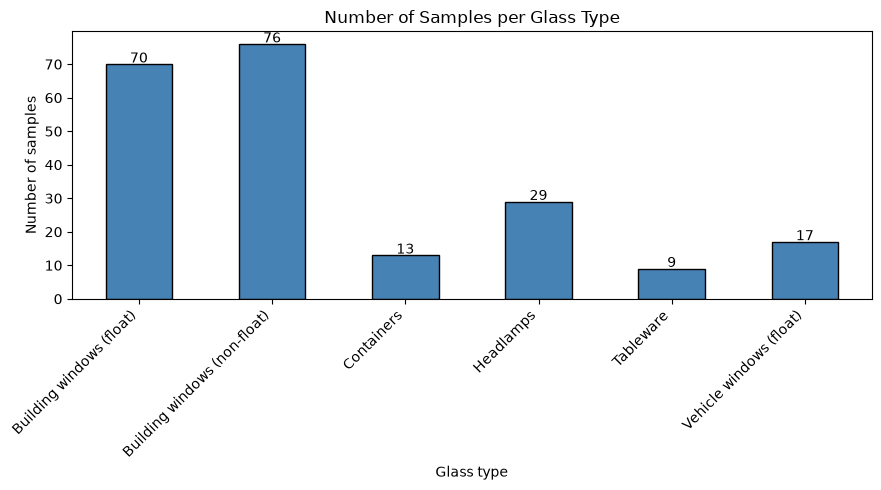

In [15]:
plt.figure(figsize=(9, 5))
counts.sort_index().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Number of Samples per Glass Type')
plt.xlabel('Glass type')
plt.ylabel('Number of samples')
plt.xticks(rotation=45, ha='right')
for i, v in enumerate(counts.sort_index().values):
    plt.text(i, v + 0.5, str(v), ha='center')
plt.tight_layout()
plt.show()

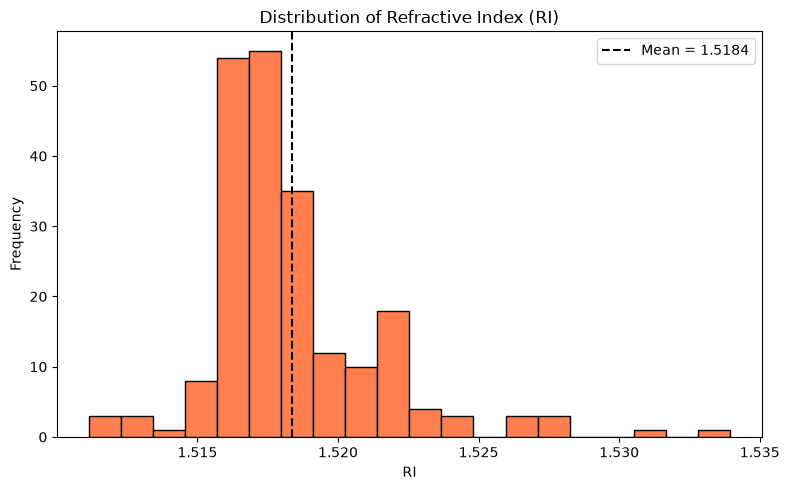

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df['RI'].to_numpy(), bins=20, color='coral', edgecolor='black')
plt.axvline(df['RI'].mean(), color='black', linestyle='--', label=f"Mean = {df['RI'].mean():.4f}")
plt.title('Distribution of Refractive Index (RI)')
plt.xlabel('RI')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
biggest = counts.idxmax()
smallest = counts.idxmin()
print(f"1. Class imbalance: '{biggest}' has the most samples ({counts.max()}), "
      f"while '{smallest}' has the fewest ({counts.min()}). Type 4 has no samples at all.")

print(f"2. Magnesium: '{mg_avg.idxmax()}' has the highest average Mg ({mg_avg.max():.2f}), "
      f"and '{mg_avg.idxmin()}' the lowest ({mg_avg.min():.2f}), so Mg differs a lot between glass types.")

ba_top = group_means['Ba'].idxmax()
print(f"3. Barium (Ba) is highest on average in '{ba_top}' ({group_means['Ba'].max():.2f}); "
      f"{(group_means['Ba'] < 0.1).sum()} of {len(group_means)} types have an average Ba below 0.1, so Ba helps separate glass types.")

1. Class imbalance: 'Building windows (non-float)' has the most samples (76), while 'Tableware' has the fewest (9). Type 4 has no samples at all.
2. Magnesium: 'Building windows (float)' has the highest average Mg (3.55), and 'Headlamps' the lowest (0.54), so Mg differs a lot between glass types.
3. Barium (Ba) is highest on average in 'Headlamps' (1.04); 4 of 6 types have an average Ba below 0.1, so Ba helps separate glass types.
